<a href="https://colab.research.google.com/github/zranadegirmenci/veri-analizi-projeleri/blob/main/hastane_randevu_ve_kapasite_analitigi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sağlık Bilişimi Operasyonel Veri Simülasyonu (300 Hasta Kaydı)
np.random.seed(42)
n_records = 300

poliklinikler = ['Kardiyoloji', 'Ortopedi', 'Dahiliye', 'Nöroloji', 'Göz Hastalıkları']
randevu_tipleri = ['İlk Muayene', 'Kontrol', 'Rutin Tetkik']

veri = {
    'Protokol_No': [10000 + i for i in range(n_records)],
    'Poliklinik': np.random.choice(poliklinikler, size=n_records, p=[0.25, 0.20, 0.30, 0.15, 0.10]),
    'Randevu_Tipi': np.random.choice(randevu_tipleri, size=n_records, p=[0.50, 0.30, 0.20]),
    'Bekleme_Suresi_Dk': np.random.gamma(shape=3.5, scale=8, size=n_records).round(1), # Ortalama ~28 dk
    'Muayene_Suresi_Dk': np.random.normal(loc=15, scale=4, size=n_records).round(1),   # Ortalama ~15 dk
    'Randevu_Durumu': np.random.choice(['Geldi', 'Gelmeyen (No-Show)'], size=n_records, p=[0.82, 0.18]),
    'Hasta_Memnuniyet_Puani': np.random.choice([1, 2, 3, 4, 5, np.nan], size=n_records, p=[0.05, 0.08, 0.20, 0.35, 0.27, 0.05])
}

df_saglik = pd.DataFrame(veri)

# EDA Çıktıları
print("--- Veri Seti Boyutu ---")
print(df_saglik.shape)

print("\n--- İlk 5 Hasta Kaydı ---")
print(df_saglik.head())

print("\n--- Eksik Değer Kontrolü (Missing Values) ---")
print(df_saglik.isnull().sum())

print("\n--- Sayısal Süre Dağılımları (Dakika) ---")
print(df_saglik[['Bekleme_Suresi_Dk', 'Muayene_Suresi_Dk']].describe().T[['mean', 'std', 'min', 'max']])

--- Veri Seti Boyutu ---
(300, 7)

--- İlk 5 Hasta Kaydı ---
   Protokol_No        Poliklinik Randevu_Tipi  Bekleme_Suresi_Dk  \
0        10000          Ortopedi  İlk Muayene               18.5   
1        10001  Göz Hastalıkları      Kontrol               15.6   
2        10002          Dahiliye      Kontrol               23.8   
3        10003          Dahiliye      Kontrol               13.3   
4        10004       Kardiyoloji      Kontrol               64.9   

   Muayene_Suresi_Dk Randevu_Durumu  Hasta_Memnuniyet_Puani  
0               11.1          Geldi                     3.0  
1               14.8          Geldi                     4.0  
2               15.0          Geldi                     2.0  
3               10.4          Geldi                     3.0  
4               21.0          Geldi                     4.0  

--- Eksik Değer Kontrolü (Missing Values) ---
Protokol_No                0
Poliklinik                 0
Randevu_Tipi               0
Bekleme_Suresi_Dk       

# 1. Poliklinik Bazında Hasta Bekleme Süreleri (Operasyonel Darboğaz Analizi)
Hastanenin poliklinik bazlı hasta yükü ve randevu öncesi bekleme süreleri incelenerek kapasite darboğazı yaşayan birimler tespit edilmiştir.

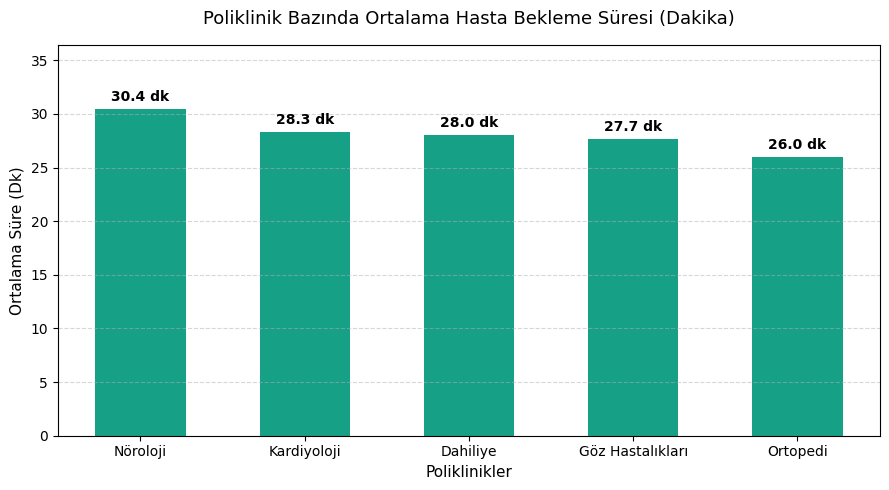

In [21]:
# Poliklinik bazında ortalama bekleme sürelerini hesaplama ve sıralama
bekleme_analizi = df_saglik.groupby('Poliklinik', observed=False)['Bekleme_Suresi_Dk'].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
cubuklar = plt.bar(bekleme_analizi.index, bekleme_analizi.values, color='#16a085', width=0.55)

plt.title('Poliklinik Bazında Ortalama Hasta Bekleme Süresi (Dakika)', fontsize=13, pad=15)
plt.ylabel('Ortalama Süre (Dk)', fontsize=11)
plt.xlabel('Poliklinikler', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Barların üzerine net süreleri yazdırma
for bar in cubuklar:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.1f} dk", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, max(bekleme_analizi.values) + 6)
plt.tight_layout()
plt.show()

# 1.1. Poliklinik Bazında Bekleme Süresi Dağılımı ve Aykırı Değer Analizi (Boxplot)
Ortalamanın gizlediği medyan değerleri ve olağandışı uzun bekleyen aykırı hasta vakalarını tespit etmek için kutu grafiği kullanılmıştır.

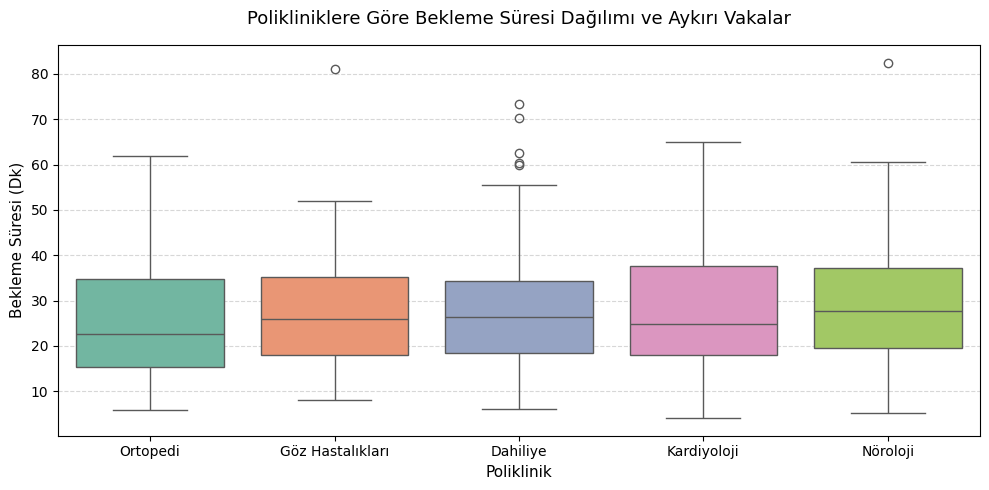

In [22]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='Poliklinik', y='Bekleme_Suresi_Dk', data=df_saglik, hue='Poliklinik', palette='Set2', legend=False)

plt.title('Polikliniklere Göre Bekleme Süresi Dağılımı ve Aykırı Vakalar', fontsize=13, pad=15)
plt.xlabel('Poliklinik', fontsize=11)
plt.ylabel('Bekleme Süresi (Dk)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 1.2. Randevu Tipi ve Poliklinik Kesişiminde Muayene Süresi Matrisi (Pivot Table)
Poliklinik ve randevu türlerinin kesişiminde ortalama muayene süreleri çapraz tablo olarak özetlenmiştir.

In [23]:
pivot_tablo = df_saglik.pivot_table(
    index='Poliklinik',
    columns='Randevu_Tipi',
    values='Muayene_Suresi_Dk',
    aggfunc='mean'
).round(1)

print("--- Poliklinik x Randevu Tipi Ortalama Muayene Süresi (Dk) ---")
print(pivot_tablo)

--- Poliklinik x Randevu Tipi Ortalama Muayene Süresi (Dk) ---
Randevu_Tipi      Kontrol  Rutin Tetkik  İlk Muayene
Poliklinik                                          
Dahiliye             13.6          16.3         15.7
Göz Hastalıkları     15.4          13.5         16.0
Kardiyoloji          14.7          16.6         14.2
Nöroloji             15.4          18.2         14.8
Ortopedi             15.4          15.6         16.4


# 2. Hasta Randevu Sadakati ve Gelmeme (No-Show) Analizi
Randevu alan hastaların gerçekleşme oranları analiz edilmiş, doktor ve oda kapasitesini boşa çıkaran 'No-Show' hacmi modellenmiştir.

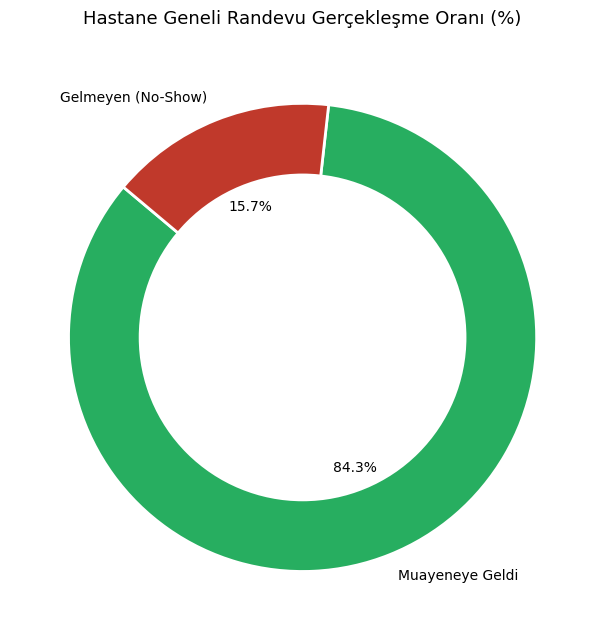

In [24]:
# Randevu gerçekleşme dağılımı
randevu_dagilim = df_saglik['Randevu_Durumu'].value_counts()

etiketler = ['Muayeneye Geldi', 'Gelmeyen (No-Show)']
renkler = ['#27ae60', '#c0392b'] # Yeşil vs Kırmızı

plt.figure(figsize=(6.5, 6.5))
plt.pie(
    randevu_dagilim.values,
    labels=etiketler,
    autopct='%1.1f%%',
    startangle=140,
    colors=renkler,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

# Ortasını delerek halka grafiğe dönüştürme
merkez = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(merkez)

plt.title('Hastane Geneli Randevu Gerçekleşme Oranı (%)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

# 3. Bekleme Süresinin Hasta Memnuniyeti Üzerindeki Etkisi
Hastaların bekleme sürelerinin (dk) hizmet sonrası verilen memnuniyet puanlarına (1-5) etkisi incelenmiştir.

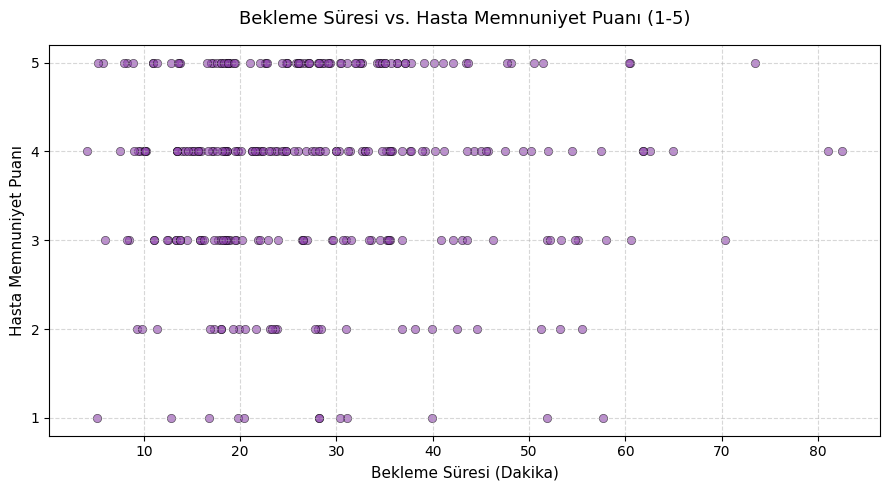

In [25]:
# Eksik memnuniyet puanlarını hariç tutarak analiz etme
df_memnuniyet = df_saglik.dropna(subset=['Hasta_Memnuniyet_Puani'])

plt.figure(figsize=(9, 5))
plt.scatter(df_memnuniyet['Bekleme_Suresi_Dk'], df_memnuniyet['Hasta_Memnuniyet_Puani'], color='#8e44ad', alpha=0.6, edgecolors='black', linewidth=0.5)

plt.title('Bekleme Süresi vs. Hasta Memnuniyet Puanı (1-5)', fontsize=13, pad=15)
plt.xlabel('Bekleme Süresi (Dakika)', fontsize=11)
plt.ylabel('Hasta Memnuniyet Puanı', fontsize=11)
plt.yticks([1, 2, 3, 4, 5])
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 4. Hastane Yönetim Özeti ve Klinik Verimlilik Aksiyon Planı

Poliklinik operasyon verilerinin uçtan uca analizi sonucunda hastane yönetimi için aşağıdaki aksiyonlar önerilmektedir:

* **Dinamik Randevu Aralıkları:** Bekleme süresinin en yüksek çıktığı polikliniklerde randevu aralıkları sabit 15 dakika yerine, tetkik ve kontrol yoğunluğuna göre dinamik olarak 20-25 dakikaya esnetilmelidir.
* **No-Show Azaltma Otomasyonu:** %18 civarındaki randevuya gelmeme (No-Show) oranını düşürmek ve atıl doktor kapasitesini önlemek adına randevudan 24 saat önce SMS/WhatsApp teyit botu devreye alınmalıdır.
* **Kapasite ve Hekim Dengelemesi:** Bekleme süresi 30 dakikayı aşan polikliniklerde hasta memnuniyet puanının belirgin şekilde düştüğü tespit edilmiş olup, yoğun saatlerde polikliniklere asistan hekim desteği sağlanmalıdır.